### Slope function

In [2]:
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


'''def slope(x, y):
    # calculate the slope for every 5 steps
    slope_s = []

    for i in range(len(x)):
        # for the first element, simple slope evaluate
        if i == 0 :
            tem1 = (y[i+1]-y[i])/(x[i+1]-x[i])
            slope_s.append(tem1)

        # for the elements of second and the second from the last, central slope calculate
        elif i == (len(x)-1):
            tem2 = (y[i]-y[i-1])/(x[i]-x[i-1])
            slope_s.append(tem2)

        else:
            tem3 = (y[i+1]-y[i-1])/(x[i+1]-x[i-1])
            slope_s.append(tem3)

    slope_s = np.array(slope_s)

    return slope_s'''

def slope(x, y):
    # calculate the slope for every 5 steps
    slope_s = []

    for i in range(len(x)):
        # for the first element, simple slope evaluate
        if i == 0 :
            tem1 = (y[i+1]-y[i])/(x[i+1]-x[i])
            slope_s.append(tem1)

        # for the elements of second and the second from the last, central slope calculate
        elif i == 1 :
            tem2 = (y[i+1]-y[i-1])/(x[i+1]-x[i-1])
            slope_s.append(tem2)

        elif i == (len(x)-2):
            tem3 = (y[i+1]-y[i-1])/(x[i+1]-x[i-1])
            slope_s.append(tem3)

        elif i == (len(x)-1):
            tem4 = (y[i]-y[i-1])/(x[i]-x[i-1])
            slope_s.append(tem4)

        else:
            tem5 = (y[i+2]-y[i-2])/(x[i+2]-x[i-2])
            slope_s.append(tem5)

    slope_s = np.array(slope_s)

    return slope_s


### Import two variables (x, y)

In [3]:
# Import datasets
data_area = np.load('gleamgpm_0615_pversion_allpoint_area.npy')
data_con = np.load('gleamgpm_0615_pversion_allpoint_con.npy')

group  = np.loadtxt("group_fix_4groups.txt") # Grid like spatial groups
kg = []

for i in range(44):
    for j in range(38):
        if group[i,j] != 0:
          kg.append(group[i,j])

# g1
g1_con = []
g1_area = []
g2_con = []
g2_area = []
g3_con = []
g3_area = []
g4_con = []
g4_area = []

cal = 0
for i in range(int(len(kg))):

    if kg[cal] == 1:
        g1_con.append(data_con[cal,:])
        g1_area.append(data_area[cal,:])

    if kg[cal] == 2:
        g2_con.append(data_con[cal,:])
        g2_area.append(data_area[cal,:])

    if kg[cal] == 3:
        g3_con.append(data_con[cal,:])
        g3_area.append(data_area[cal,:])

    if kg[cal] == 4:
        g4_con.append(data_con[cal,:])
        g4_area.append(data_area[cal,:])

    cal = cal + 1

g1_con = np.array(g1_con)
g1_area = np.array(g1_area)
g2_con = np.array(g2_con)
g2_area = np.array(g2_area)
g3_con = np.array(g3_con)
g3_area = np.array(g3_area)
g4_con = np.array(g4_con)
g4_area = np.array(g4_area)


### Interpolate and Calculate the peaks

In [10]:
# g1
g1_ac_max = []
g1_r = []
g1_xdata = []
g1_ydata = []

for i in range(np.shape(g1_area)[0]):
    tem_con = g1_con[i,:]
    tem_area = g1_area[i,:]

    # Shift data to avoid log(0), assuming small a ≈ min(y_data)/10
    a = np.min(tem_area[tem_area > 0]) / 10
    y_shifted = tem_area + a  # Shift data to avoid zero issues

    # Perform linear interpolation in log-space
    log_y_data = np.log(y_shifted)
    linear_interp = interp1d(tem_con, log_y_data, kind='linear', fill_value="extrapolate")

    # Generate interpolated values
    x_interp = np.linspace(min(tem_con), max(tem_con), 1000)
    y_interp = np.exp(linear_interp(x_interp)) - a  # Convert back and shift
    y_interp = y_interp/10 # To sure the scale of y-axis is same as the scale of x-axis

    slope_tem = slope(x_interp,y_interp) # Calculate slope
    angle_degrees = np.arctan(slope_tem) * (180 / np.pi) # From slope to degree
    angle_change = np.gradient(angle_degrees) # Degree change rate

    r = medfilt(angle_change, kernel_size=15) # Apply Median Filtering
    r = gaussian_filter1d(r, sigma=10) # Apply Gaussian Filter

    peaks, _1 = find_peaks(r, prominence=0.05) # Find peaks
    g1_ac_max.append(x_interp[peaks])
    g1_r.append(r)
    g1_xdata.append(x_interp)
    g1_ydata.append(y_interp*10)

g1_r = np.array(g1_r)
g1_xdata = np.array(g1_xdata)
g1_ydata = np.array(g1_ydata)

# g2
g2_ac_max = []
g2_r = []
g2_xdata = []
g2_ydata = []

for i in range(np.shape(g2_area)[0]):
    tem_con = g2_con[i,:]
    tem_area = g2_area[i,:]

    # Shift data to avoid log(0), assuming small a ≈ min(y_data)/10
    a = np.min(tem_area[tem_area > 0]) / 10
    y_shifted = tem_area + a  # Shift data to avoid zero issues

    # Perform linear interpolation in log-space
    log_y_data = np.log(y_shifted)
    linear_interp = interp1d(tem_con, log_y_data, kind='linear', fill_value="extrapolate")

    # Generate interpolated values
    x_interp = np.linspace(min(tem_con), max(tem_con), 1000)
    y_interp = np.exp(linear_interp(x_interp)) - a  # Convert back and shift
    y_interp = y_interp/10 # To sure the scale of y-axis is same as the scale of x-axis

    slope_tem = slope(x_interp,y_interp) # Calculate slope
    angle_degrees = np.arctan(slope_tem) * (180 / np.pi) # From slope to degree
    angle_change = np.gradient(angle_degrees) # Degree change rate

    r = medfilt(angle_change, kernel_size=15) # Apply Median Filtering
    r = gaussian_filter1d(r, sigma=10) # Apply Gaussian Filter

    peaks, _1 = find_peaks(r, prominence=0.05) # Find peaks
    g2_ac_max.append(x_interp[peaks])
    g2_r.append(r)
    g2_xdata.append(x_interp)
    g2_ydata.append(y_interp*10)

g2_r = np.array(g2_r)
g2_xdata = np.array(g2_xdata)
g2_ydata = np.array(g2_ydata)

# g3
g3_ac_max = []
g3_r = []
g3_xdata = []
g3_ydata = []

for i in range(np.shape(g3_area)[0]):
    tem_con = g3_con[i,:]
    tem_area = g3_area[i,:]

    # Shift data to avoid log(0), assuming small a ≈ min(y_data)/10
    a = np.min(tem_area[tem_area > 0]) / 10
    y_shifted = tem_area + a  # Shift data to avoid zero issues

    # Perform linear interpolation in log-space
    log_y_data = np.log(y_shifted)
    linear_interp = interp1d(tem_con, log_y_data, kind='linear', fill_value="extrapolate")

    # Generate interpolated values
    x_interp = np.linspace(min(tem_con), max(tem_con), 1000)
    y_interp = np.exp(linear_interp(x_interp)) - a  # Convert back and shift
    y_interp = y_interp/10 # To sure the scale of y-axis is same as the scale of x-axis

    slope_tem = slope(x_interp,y_interp) # Calculate slope
    angle_degrees = np.arctan(slope_tem) * (180 / np.pi) # From slope to degree
    angle_change = np.gradient(angle_degrees) # Degree change rate

    r = medfilt(angle_change, kernel_size=15) # Apply Median Filtering
    r = gaussian_filter1d(r, sigma=10) # Apply Gaussian Filter

    peaks, _1 = find_peaks(r, prominence=0.05) # Find peaks
    g3_ac_max.append(x_interp[peaks])
    g3_r.append(r)
    g3_xdata.append(x_interp)
    g3_ydata.append(y_interp*10)

g3_r = np.array(g3_r)
g3_xdata = np.array(g3_xdata)
g3_ydata = np.array(g3_ydata)

# g4
g4_ac_max = []
g4_r = []
g4_xdata = []
g4_ydata = []

for i in range(np.shape(g4_area)[0]):
    tem_con = g4_con[i,:]
    tem_area = g4_area[i,:]

    # Shift data to avoid log(0), assuming small a ≈ min(y_data)/10
    a = np.min(tem_area[tem_area > 0]) / 10
    y_shifted = tem_area + a  # Shift data to avoid zero issues

    # Perform linear interpolation in log-space
    log_y_data = np.log(y_shifted)
    linear_interp = interp1d(tem_con, log_y_data, kind='linear', fill_value="extrapolate")

    # Generate interpolated values
    x_interp = np.linspace(min(tem_con), max(tem_con), 1000)
    y_interp = np.exp(linear_interp(x_interp)) - a  # Convert back and shift
    y_interp = y_interp/10 # To sure the scale of y-axis is same as the scale of x-axis

    slope_tem = slope(x_interp,y_interp) # Calculate slope
    angle_degrees = np.arctan(slope_tem) * (180 / np.pi) # From slope to degree
    angle_change = np.gradient(angle_degrees) # Degree change rate

    r = medfilt(angle_change, kernel_size=15) # Apply Median Filtering
    r = gaussian_filter1d(r, sigma=10) # Apply Gaussian Filter

    peaks, _1 = find_peaks(r, prominence=0.05) # Find peaks
    g4_ac_max.append(x_interp[peaks])
    g4_r.append(r)
    g4_xdata.append(x_interp)
    g4_ydata.append(y_interp*10)

g4_r = np.array(g4_r)
g4_xdata = np.array(g4_xdata)
g4_ydata = np.array(g4_ydata)

### Plot results of four groups (Figure 3b)

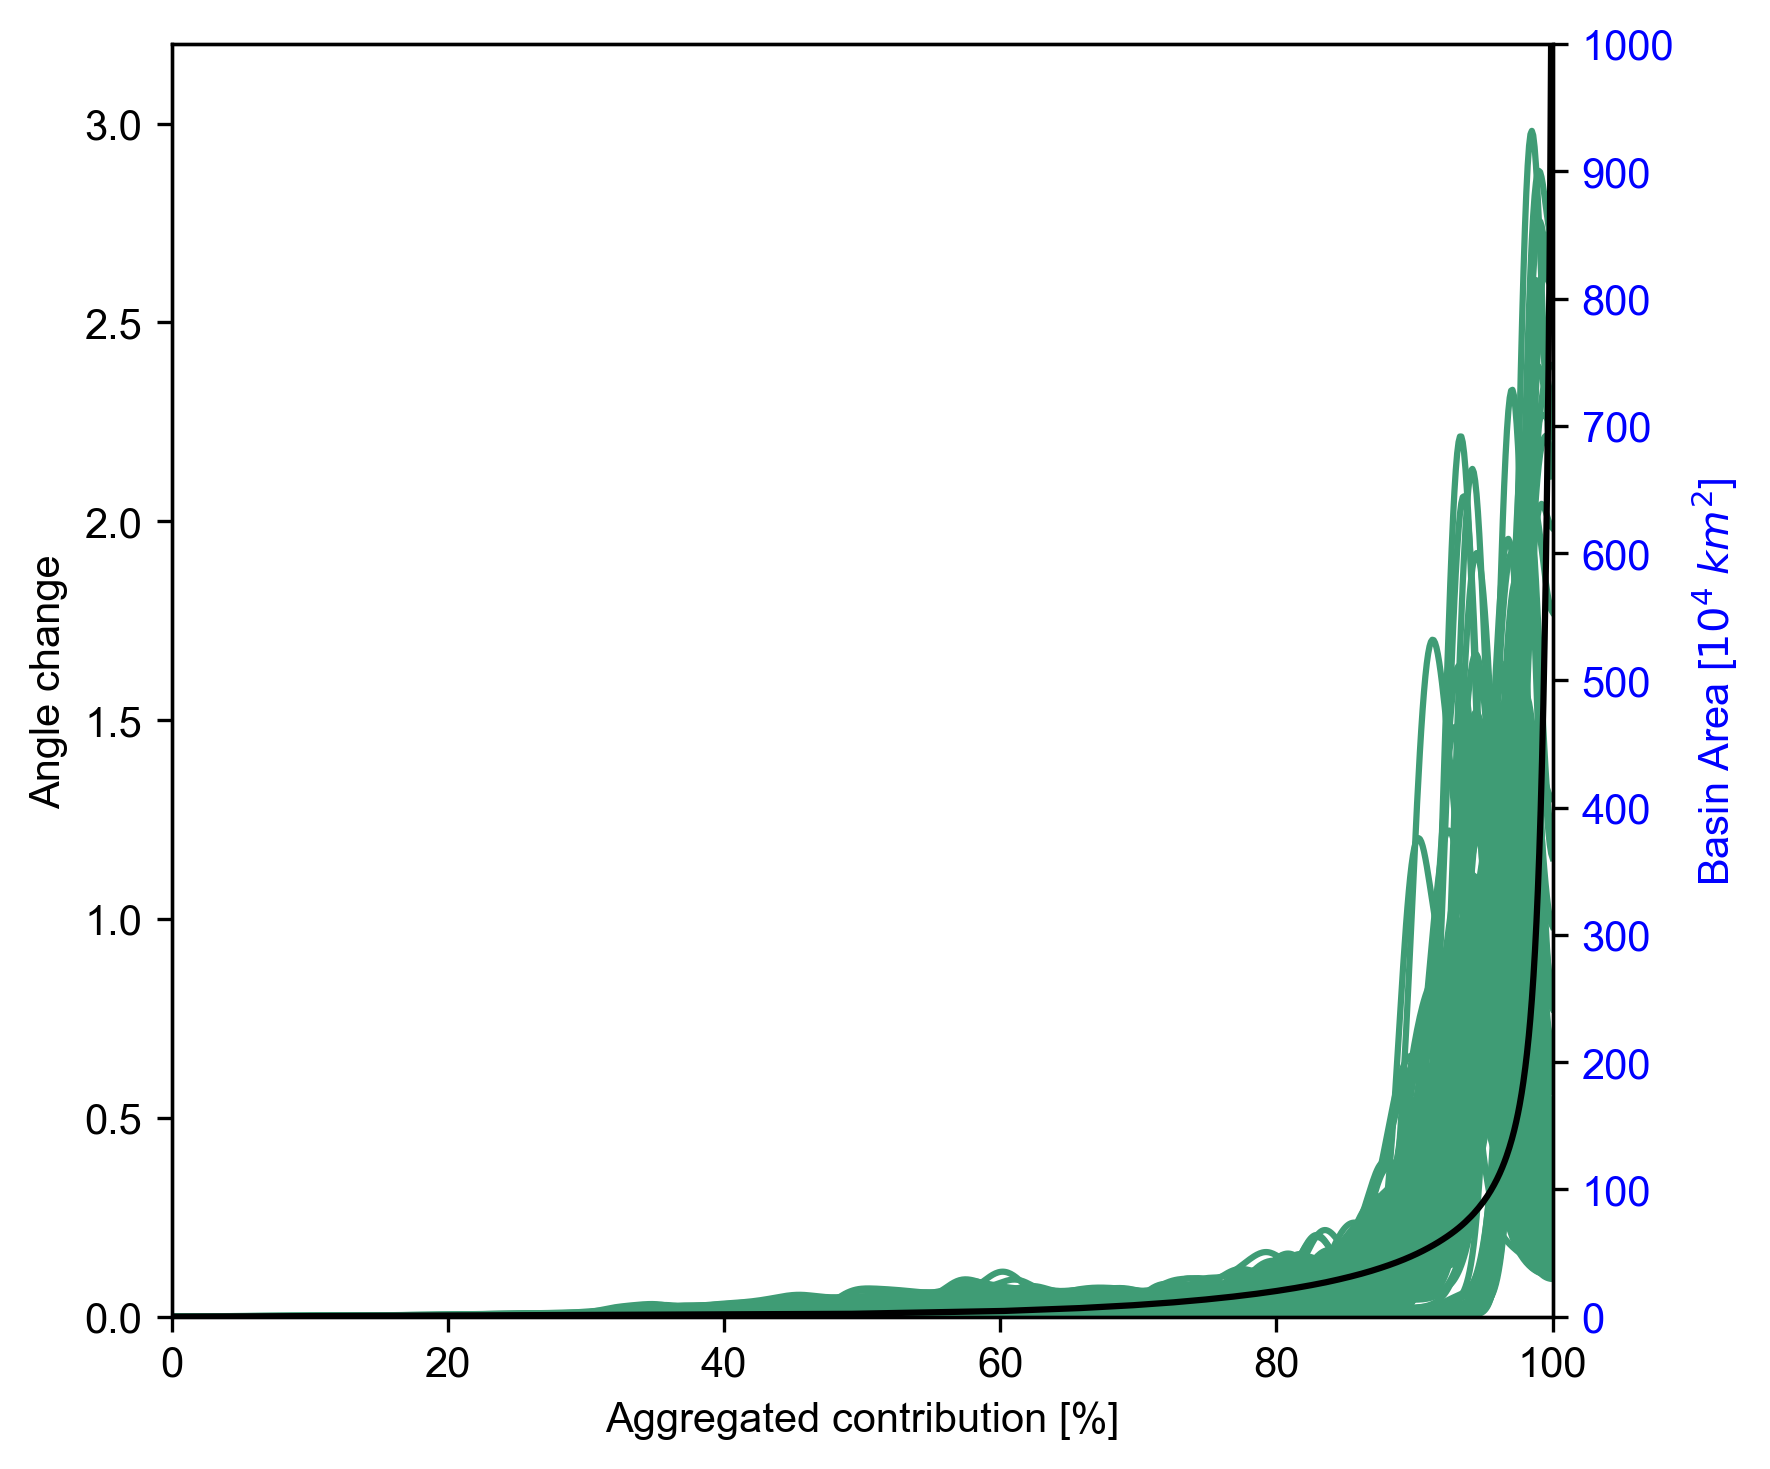

In [11]:
# Plot the tangent angles
fig, ax1 = plt.subplots(figsize=(6, 5), dpi=300)

x_levels = np.array([0,20,40,60,80,100])
y_levels1 = np.array([0,0.5,1,1.5,2,2.5,3])
y_levels2 = np.array([0,100,200,300,400,500,600,700,800,900,1000])

for i in range(np.shape(g1_r)[0]):
    ax1.plot(g1_xdata[i,:], g1_r[i,:], color="#3F9C75")

g1_xmean = np.mean(g1_con,axis = 0)
g1_ymean = np.mean(g1_area,axis = 0)

ax1.set_xlabel("Aggregated contribution [%]", fontsize=10,
    fontname="Arial")
ax1.set_ylabel("Angle change", fontsize=10,
    fontname="Arial")

ax1.set_xticks(x_levels)
ax1.set_xticklabels(x_levels, fontname="Arial", fontsize=10)
ax1.set_yticks(y_levels1)
ax1.set_yticklabels(y_levels1, fontname="Arial", fontsize=10)
ax1.set_ylim(0, 3.2)

# Create secondary y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(g1_xmean, g1_ymean, color="k")
ax2.set_ylabel(r'Basin Area [$10^4$ $km^2$]', fontsize=10, fontname="Arial", color="blue")
ax2.tick_params(axis='y', labelcolor="blue")
ax2.set_yticks(y_levels2)
ax2.set_yticklabels(y_levels2, fontname="Arial", fontsize=10)
ax2.set_ylim(0, 1000)

plt.xlim(0,100)

plt.tight_layout()
plt.show()

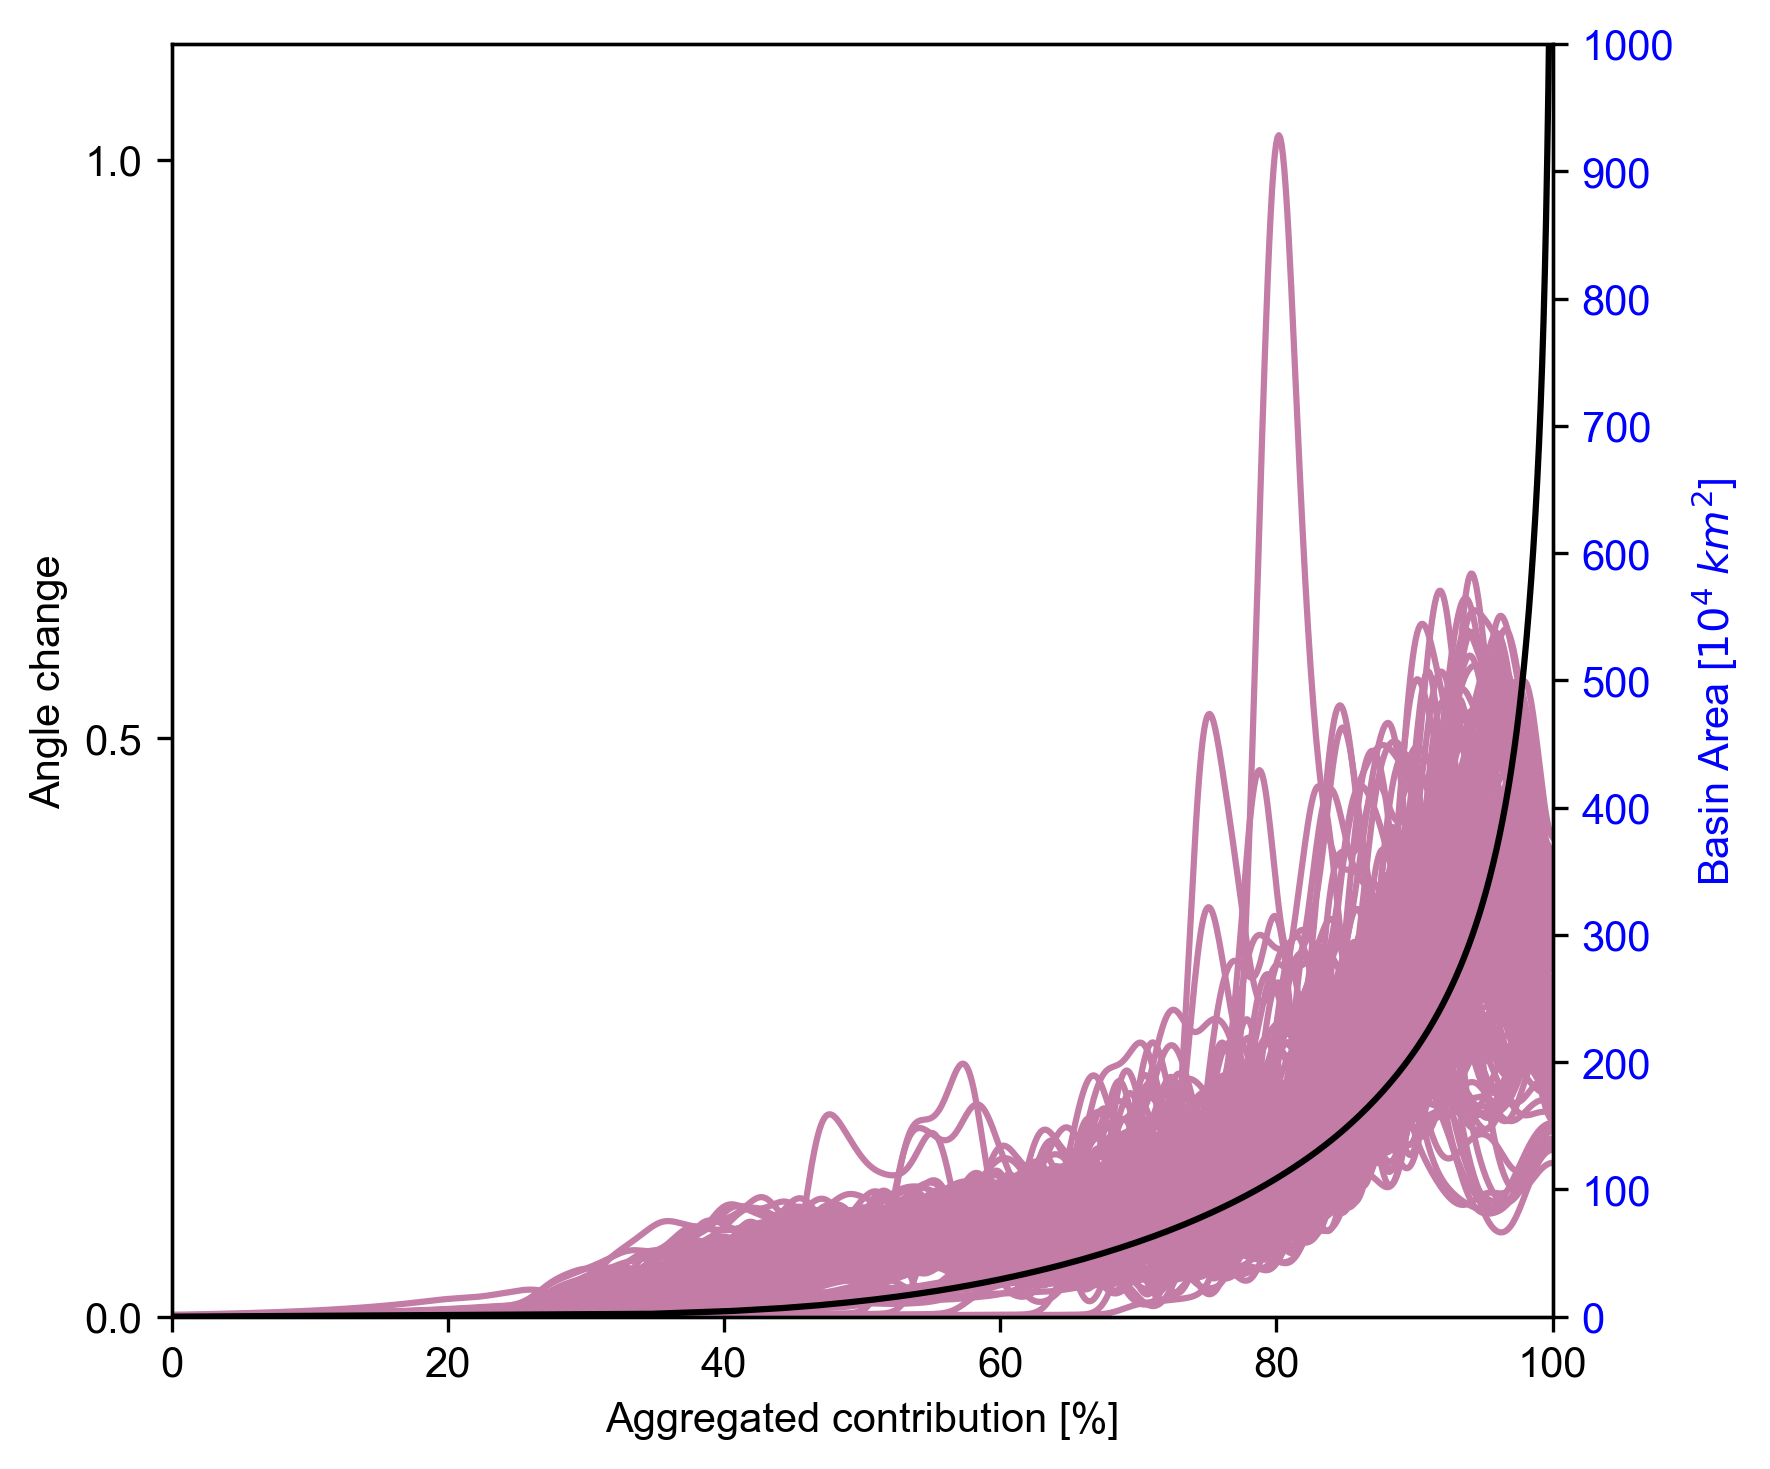

In [12]:
# Plot the tangent angles
fig, ax1 = plt.subplots(figsize=(6, 5), dpi=300)

x_levels = np.array([0,20,40,60,80,100])
y_levels1 = np.array([0,0.5,1,1.5,2,2.5,3])
y_levels2 = np.array([0,100,200,300,400,500,600,700,800,900,1000])

for i in range(np.shape(g2_r)[0]):
    ax1.plot(g2_xdata[i,:], g2_r[i,:], color="#C37CA6")

g2_xmean = np.mean(g2_con,axis = 0)
g2_ymean = np.mean(g2_area,axis = 0)

ax1.set_xlabel("Aggregated contribution [%]", fontsize=10,
    fontname="Arial")
ax1.set_ylabel("Angle change", fontsize=10,
    fontname="Arial")

ax1.set_xticks(x_levels)
ax1.set_xticklabels(x_levels, fontname="Arial", fontsize=10)
ax1.set_yticks(y_levels1)
ax1.set_yticklabels(y_levels1, fontname="Arial", fontsize=10)
ax1.set_ylim(0, 1.1)

# Create secondary y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(g2_xmean, g2_ymean, color="k")
ax2.set_ylabel(r'Basin Area [$10^4$ $km^2$]', fontsize=10, fontname="Arial", color="blue")
ax2.tick_params(axis='y', labelcolor="blue")
ax2.set_yticks(y_levels2)
ax2.set_yticklabels(y_levels2, fontname="Arial", fontsize=10)
ax2.set_ylim(0, 1000)

plt.xlim(0,100)

plt.tight_layout()
plt.show()

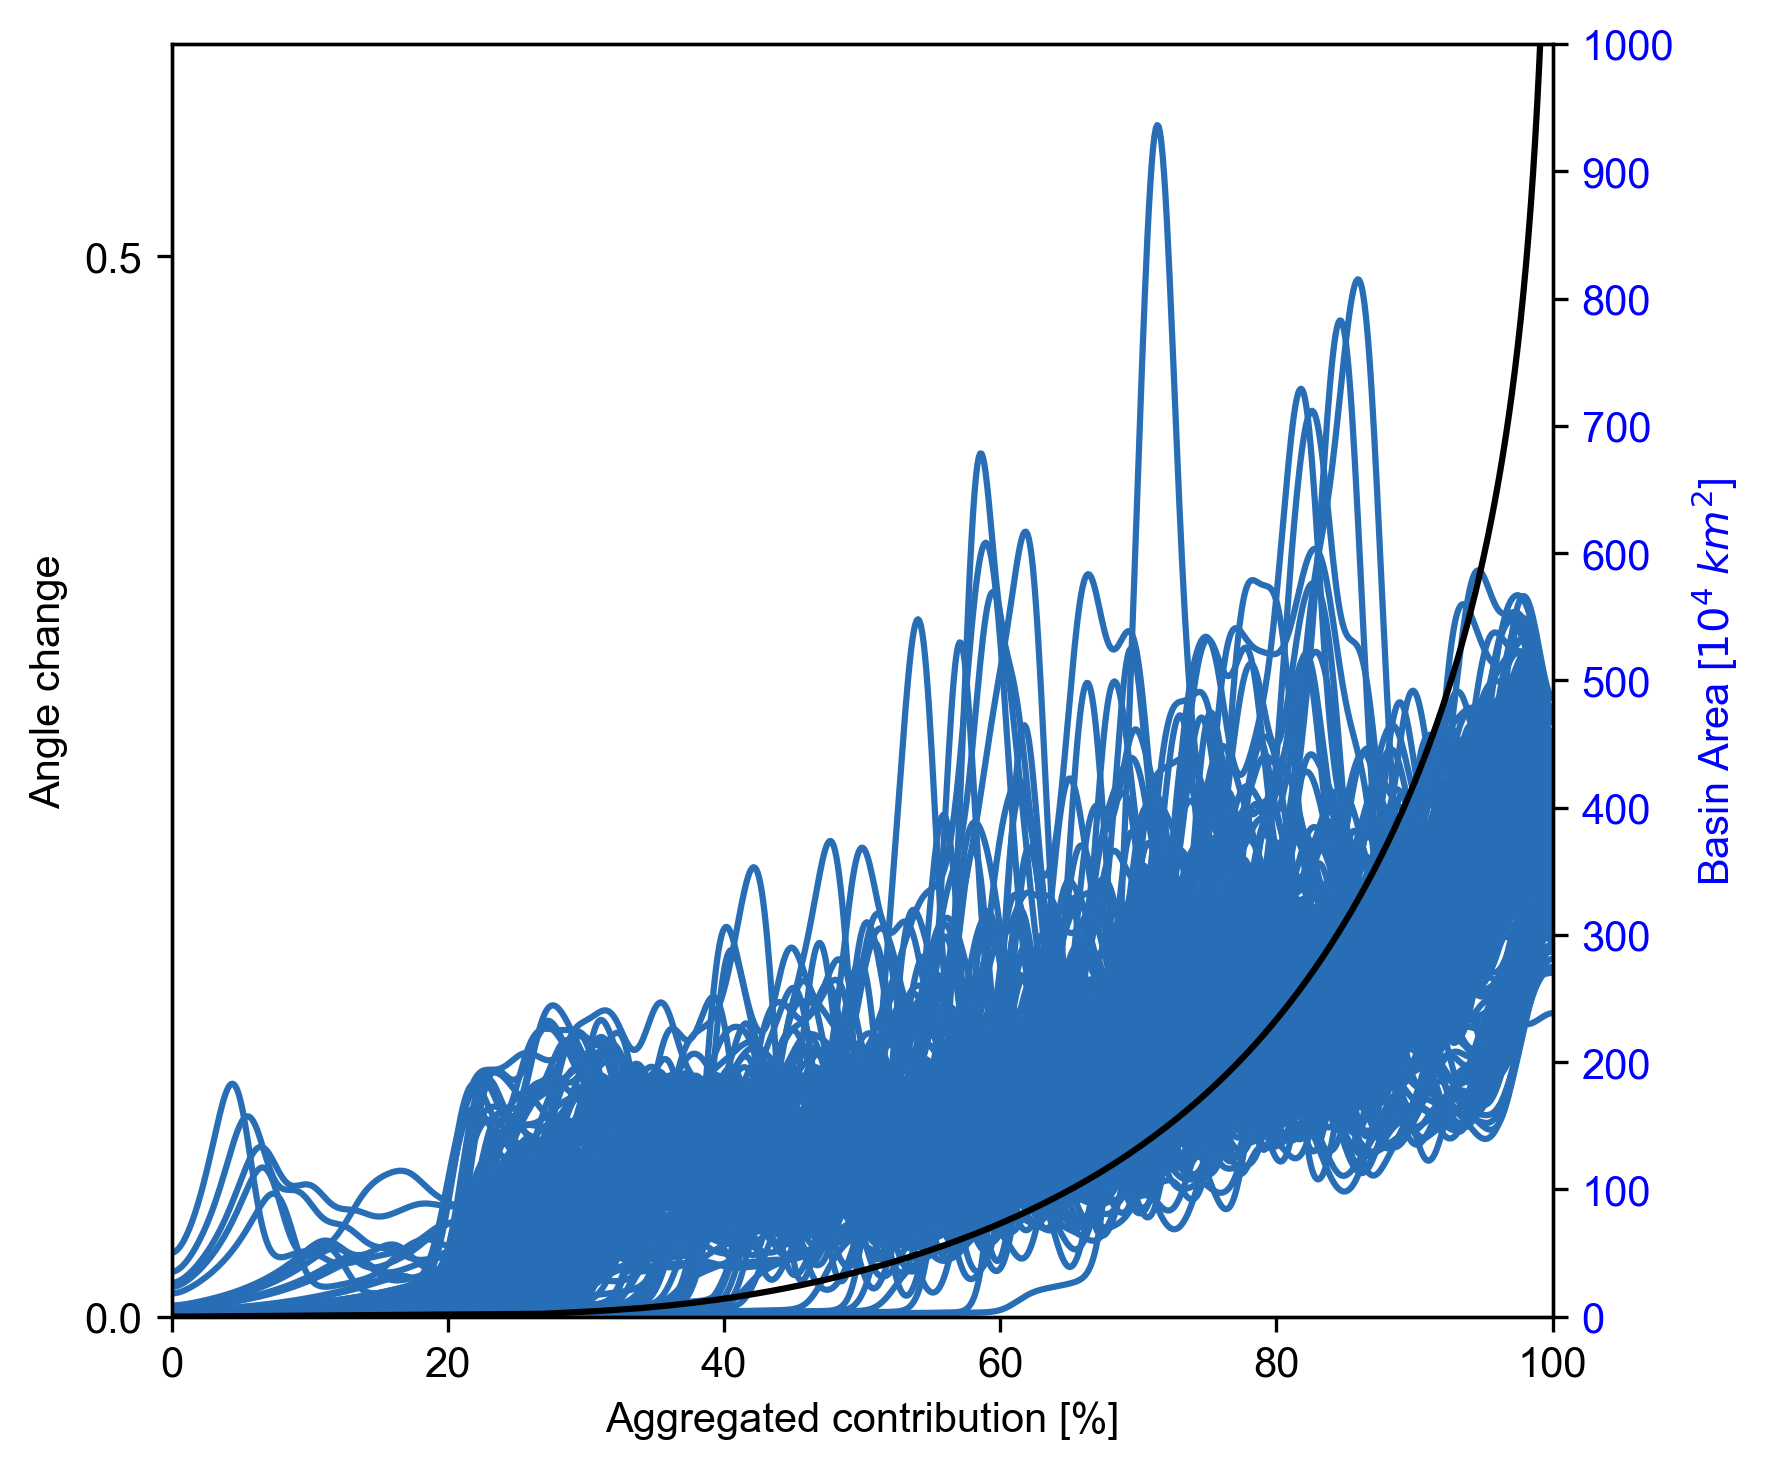

In [13]:
# Plot the tangent angles
fig, ax1 = plt.subplots(figsize=(6, 5), dpi=300)

x_levels = np.array([0,20,40,60,80,100])
y_levels1 = np.array([0,0.5,1,1.5,2,2.5,3])
y_levels2 = np.array([0,100,200,300,400,500,600,700,800,900,1000])

for i in range(np.shape(g3_r)[0]):
    ax1.plot(g3_xdata[i,:], g3_r[i,:], color="#286EB6")

g3_xmean = np.mean(g3_con,axis = 0)
g3_ymean = np.mean(g3_area,axis = 0)

ax1.set_xlabel("Aggregated contribution [%]", fontsize=10,
    fontname="Arial")
ax1.set_ylabel("Angle change", fontsize=10,
    fontname="Arial")

ax1.set_xticks(x_levels)
ax1.set_xticklabels(x_levels, fontname="Arial", fontsize=10)
ax1.set_yticks(y_levels1)
ax1.set_yticklabels(y_levels1, fontname="Arial", fontsize=10)
ax1.set_ylim(0, 0.6)

# Create secondary y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(g3_xmean, g3_ymean, color="k")
ax2.set_ylabel(r'Basin Area [$10^4$ $km^2$]', fontsize=10, fontname="Arial", color="blue")
ax2.tick_params(axis='y', labelcolor="blue")
ax2.set_yticks(y_levels2)
ax2.set_yticklabels(y_levels2, fontname="Arial", fontsize=10)
ax2.set_ylim(0, 1000)

plt.xlim(0,100)

plt.tight_layout()
plt.show()

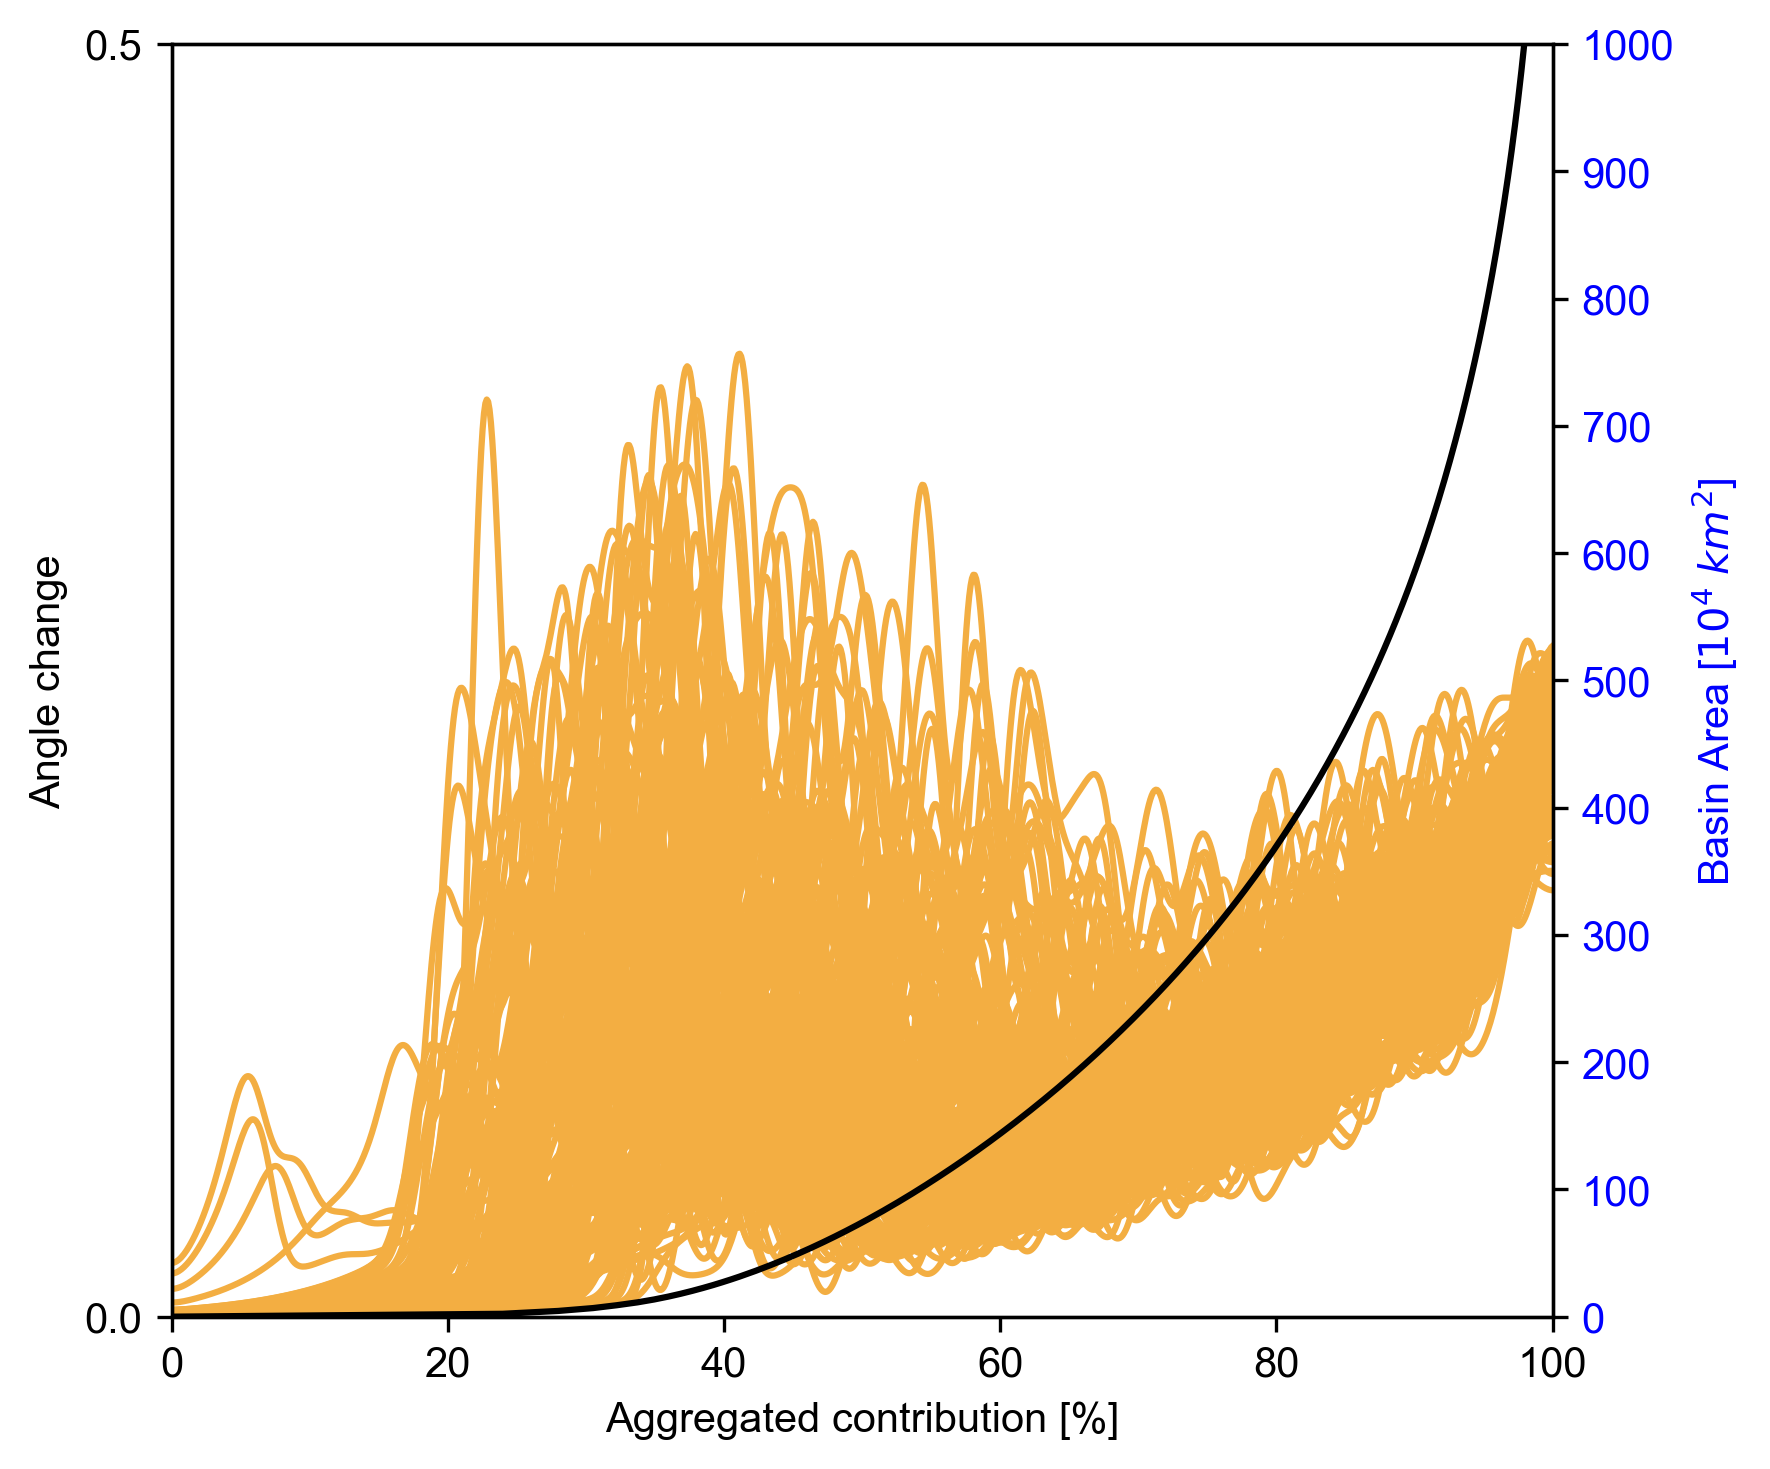

In [14]:
# Plot the tangent angles
fig, ax1 = plt.subplots(figsize=(6, 5), dpi=300)

x_levels = np.array([0,20,40,60,80,100])
y_levels1 = np.array([0,0.5,1,1.5,2,2.5,3])
y_levels2 = np.array([0,100,200,300,400,500,600,700,800,900,1000])

for i in range(np.shape(g4_r)[0]):
    ax1.plot(g4_xdata[i,:], g4_r[i,:], color="#F3AE42")

g4_xmean = np.mean(g4_con,axis = 0)
g4_ymean = np.mean(g4_area,axis = 0)

ax1.set_xlabel("Aggregated contribution [%]", fontsize=10,
    fontname="Arial")
ax1.set_ylabel("Angle change", fontsize=10,
    fontname="Arial")

ax1.set_xticks(x_levels)
ax1.set_xticklabels(x_levels, fontname="Arial", fontsize=10)
ax1.set_yticks(y_levels1)
ax1.set_yticklabels(y_levels1, fontname="Arial", fontsize=10)
ax1.set_ylim(0, 0.5)

# Create secondary y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(g4_xmean, g4_ymean, color="k")
ax2.set_ylabel(r'Basin Area [$10^4$ $km^2$]', fontsize=10, fontname="Arial", color="blue")
ax2.tick_params(axis='y', labelcolor="blue")
ax2.set_yticks(y_levels2)
ax2.set_yticklabels(y_levels2, fontname="Arial", fontsize=10)
ax2.set_ylim(0, 1000)

plt.xlim(0,100)

plt.tight_layout()
plt.show()

### Boxplot (Figure 3a)

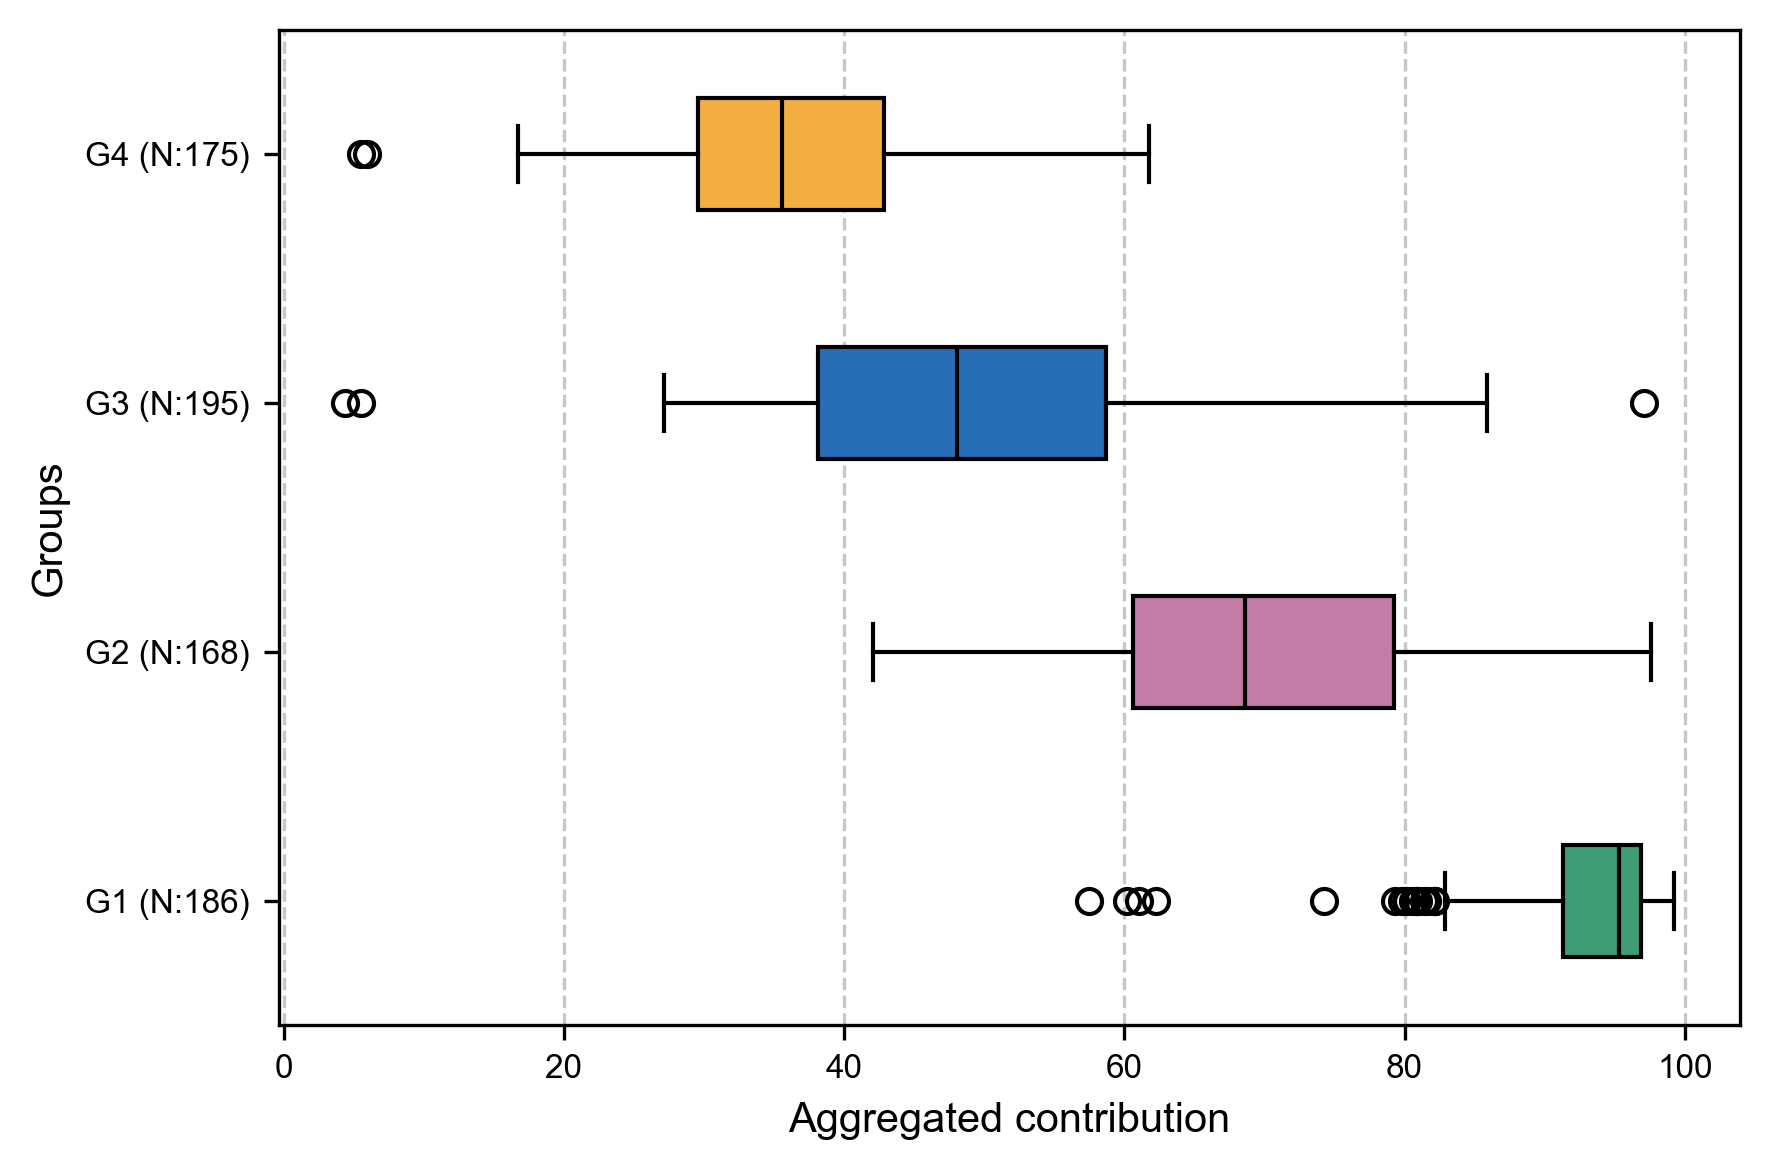

[80.58058058 80.88088088 79.77977978 81.38138138 81.58158158 82.08208208
 74.27427427 62.26226226 82.18218218 61.06106106 60.16016016 57.45745746
 80.18018018 80.98098098 82.08208208 80.08008008 79.27927928 80.78078078]
[]
[ 4.4044044   5.50550551 97.0970971 ]
[5.50550551 5.90590591]


In [15]:
g1_max = [subarray[0] if subarray.size > 0 else np.nan for subarray in g1_ac_max]
g2_max = [subarray[0] if subarray.size > 0 else np.nan for subarray in g2_ac_max]
g3_max = [subarray[0] if subarray.size > 0 else np.nan for subarray in g3_ac_max]
g4_max = [subarray[0] if subarray.size > 0 else np.nan for subarray in g4_ac_max]

g1_max = np.array(g1_max)
g2_max = np.array(g2_max)
g3_max = np.array(g3_max)
g4_max = np.array(g4_max)

g1_max = g1_max[~np.isnan(g1_max)]
g2_max = g2_max[~np.isnan(g2_max)]
g3_max = g3_max[~np.isnan(g3_max)]
g4_max = g4_max[~np.isnan(g4_max)]

# Example data
all_group = [g1_max, g2_max, g3_max, g4_max]
ticks = ['G1 (N:186)', 'G2 (N:168)', 'G3 (N:195)', 'G4 (N:175)']

# Improved boxplot
plt.figure(figsize=(6, 4), dpi=300)  # Increased size for better readability , showmeans=True
box = plt.boxplot(all_group, vert=False, patch_artist=True)

# Customize boxplot appearance
colors = ['#3F9C75', '#C37CA6', '#286EB6', '#F3AE42']
median_color = 'black'

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)


for median in box['medians']:
    median.set_color(median_color)  # Set median line color
    median.set_linewidth(1)  # Optionally, make it thicker

# Add gridlines
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Customize labels and title
plt.xlabel('Aggregated contribution', fontsize=10,
    fontname="Arial")
plt.ylabel('Groups', fontsize=10,
    fontname="Arial")
plt.xticks(fontsize=8,
    fontname="Arial")
plt.yticks(range(1, len(ticks) + 1), ticks, fontsize=8,
    fontname="Arial")  # Align y-ticks with boxplot groups
#plt.title('Where do the peek of angle change happen?', fontsize=10)

# retreiving outliers for horizontal boxplot
outliers1 = np.array(box["fliers"][0].get_xdata())
outliers2 = np.array(box["fliers"][1].get_xdata())
outliers3 = np.array(box["fliers"][2].get_xdata())
outliers4 = np.array(box["fliers"][3].get_xdata())

# Show the plot
plt.tight_layout()
plt.show()

print(outliers1)
print(outliers2)
print(outliers3)
print(outliers4)

### Calculate how many peaks were found

In [16]:
# Calculate the number of peaks the function found
g1_number_record = []
for i in range(len(g1_ac_max)):
    a = len(g1_ac_max[i])
    g1_number_record.append(a)

g2_number_record = []
for i in range(len(g2_ac_max)):
    a = len(g2_ac_max[i])
    g2_number_record.append(a)

g3_number_record = []
for i in range(len(g3_ac_max)):
    a = len(g3_ac_max[i])
    g3_number_record.append(a)

g4_number_record = []
for i in range(len(g4_ac_max)):
    a = len(g4_ac_max[i])
    g4_number_record.append(a)


# Calculate the number of peaks which is exceed 3 (May change the condition to find 2 peaks or 4 peaks)
cal1 = 0
for i in range(len(g1_number_record)):
    if g1_number_record[i] >= 3:
        cal1 = cal1+1

cal2 = 0
for i in range(len(g2_number_record)):
    if g2_number_record[i] >= 3:
        cal2 = cal2+1

cal3 = 0
for i in range(len(g3_number_record)):
    if g3_number_record[i] >= 3:
        cal3 = cal3+1

cal4 = 0
for i in range(len(g4_number_record)):
    if g4_number_record[i] >= 3:
        cal4 = cal4+1

print(cal1,cal2,cal3,cal4)

15 87 109 70


### Calculate the distance between two peaks

In [17]:
# Calculate the distance (contribution) between the two peaks
# The condition below shows the distance (contribution) between second and third peak when (peaks <= 3)

g1_dis_record = []
for i in range(len(g1_ac_max)):
    a = len(g1_ac_max[i])
    b = g1_ac_max[i]
    if a >= 3:
        distance = b[2] - b[1]
        g1_dis_record.append(distance)

g2_dis_record = []
for i in range(len(g2_ac_max)):
    a = len(g2_ac_max[i])
    b = g2_ac_max[i]
    if a >= 3:
        distance = b[2] - b[1]
        g2_dis_record.append(distance)

g3_dis_record = []
for i in range(len(g3_ac_max)):
    a = len(g3_ac_max[i])
    b = g3_ac_max[i]
    if a >= 3:
        distance = b[2] - b[1]
        g3_dis_record.append(distance)

g4_dis_record = []
for i in range(len(g4_ac_max)):
    a = len(g4_ac_max[i])
    b = g4_ac_max[i]
    if a >= 3:
        distance = b[2] - b[1]
        g4_dis_record.append(distance)

print(len(g1_dis_record))
print(len(g2_dis_record))
print(len(g3_dis_record))
print(len(g4_dis_record))

print(np.mean(g1_dis_record))
print(np.mean(g2_dis_record))
print(np.mean(g3_dis_record))
print(np.mean(g4_dis_record))

15
87
109
70
6.493159826493159
12.872642757700227
13.492391474042853
21.33276133276134


### Mean result

35.792363792363794
35.5355355355355
92.93832090443878
67.5
69.90637252293249
58.5
49.94118345629532
36.0
35.96030632907151
15.75


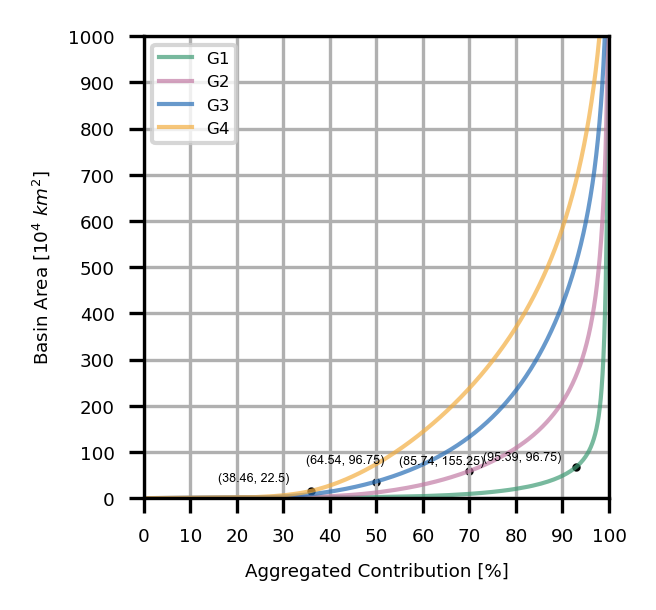

92.70264739877999 69.81028647695314 49.427376094042764 35.792363792363794
35.792363792363794


In [19]:
m1 = np.mean(g1_max)
m2 = np.mean(g2_max)
m3 = np.mean(g3_max)
m4 = np.mean(g4_max)
m4i = np.median(g4_max)

print(m4)
print(m4i)

indices1 = np.where(g1_xmean >= m1)[0]  # Find the indices where the median appears
indices2 = np.where(g2_xmean >= m2)[0]
indices3 = np.where(g3_xmean >= m3)[0]
indices4 = np.where(g4_xmean >= m4)[0]

print(g1_xmean[indices1[0]])
print(g1_ymean[indices1[0]])

print(g2_xmean[indices2[0]])
print(g2_ymean[indices2[0]])

print(g3_xmean[indices3[0]])
print(g3_ymean[indices3[0]])

print(g4_xmean[indices4[0]])
print(g4_ymean[indices4[0]])

fig, ax = plt.subplots(1, 1, figsize = [2, 2],dpi = 300)
x_levels = np.array([0,10,20,30,40,50,60,70,80,90,100])
y_levels = np.array([0,100,200,300,400,500,600,700,800,900,1000])

txt1 = '(95.39, 96.75)'
txt2 = '(85.74, 155.25)'
txt3 = '(64.54, 96.75)'
txt4 = '(38.46, 22.5)'


plt.plot(g1_xmean, g1_ymean, color = '#3F9C75', linewidth = 1,alpha=0.7)
plt.plot(g2_xmean, g2_ymean, color = '#C37CA6', linewidth = 1,alpha=0.7)
plt.plot(g3_xmean, g3_ymean, color = '#286EB6', linewidth = 1,alpha=0.7)
plt.plot(g4_xmean, g4_ymean, color = '#F3AE42', linewidth = 1,alpha=0.7)
plt.scatter(g1_xmean[indices1[0]], g1_ymean[indices1[0]], label="G1", color="k",s=1)
plt.scatter(g2_xmean[indices2[0]], g2_ymean[indices2[0]], label="G2", color="k",s=1)
plt.scatter(g3_xmean[indices3[0]], g3_ymean[indices3[0]], label="G3", color="k",s=1)
plt.scatter(g4_xmean[indices4[0]], g4_ymean[indices4[0]], label="G4", color="k",s=1)

plt.annotate(txt1, (g1_xmean[indices1[0]]-20, g1_ymean[indices1[0]]+15), fontsize = 3, fontname = 'Arial')
plt.annotate(txt2, (g2_xmean[indices2[0]]-15, g2_ymean[indices2[0]]+15), fontsize = 3, fontname = 'Arial')
plt.annotate(txt3, (g3_xmean[indices3[0]]-15, g3_ymean[indices3[0]]+40), fontsize = 3, fontname = 'Arial')
plt.annotate(txt4, (g4_xmean[indices4[0]]-20, g4_ymean[indices4[0]]+20), fontsize = 3, fontname = 'Arial')

plt.legend(['G1','G2','G3','G4'],fontsize = 4)

plt.xlim(0,100)
plt.ylim(0,1000)
plt.xticks(x_levels, fontsize = 4.4)
plt.yticks(y_levels, fontsize = 4.4)

plt.xlabel('Aggregated Contribution [%]', fontsize = 4.4)
plt.ylabel(r'Basin Area [$10^4$ $km^2$]', fontsize = 4.4)

#Ltitle = 'Moisture reception curves of different types\n[2006-2015]'
#Rtitle = ' [2006-2015]'
#ax.set_title(Ltitle, loc = 'left', fontsize = 4.4)
#ax.set_title(Rtitle, loc = 'right', fontsize = 4)
plt.grid()

plt.show()
#print(m3)

print(m1,m2,m3,m4)
print(np.mean(g4_max))

### Median result (Figure S5)

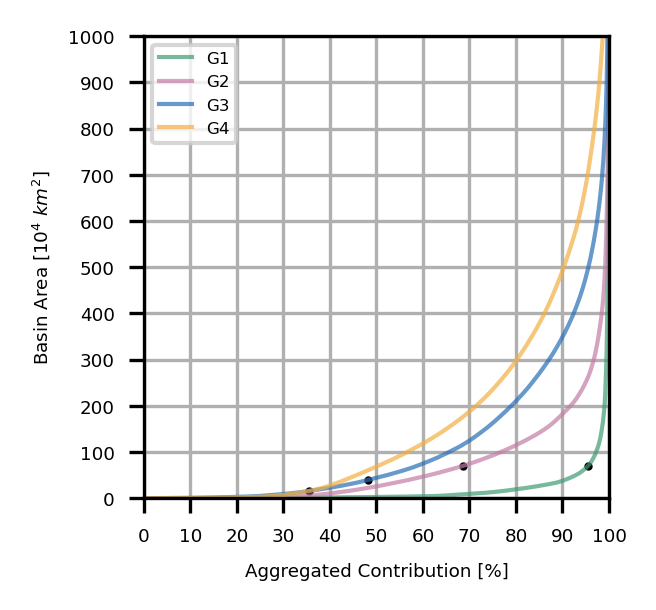

95.39539539539533 68.94922136333501
68.66866866866873 70.13395921860308
48.148148148148124 39.29994153828958
35.535535535535516 15.710991915191656
95.29529529529538 68.61861861861854 48.0480480480481 35.5355355355355
35.792363792363794


In [21]:
m1 = np.median(g1_max)
m2 = np.median(g2_max)
m3 = np.median(g3_max)
m4 = np.median(g4_max)

indices1 = np.where(g1_max >= m1)[0]  # Find the indices where the median line appears (line)
indices2 = np.where(g2_max >= m2)[0]
indices3 = np.where(g3_max >= m3)[0]
indices4 = np.where(g4_max >= m4)[0]

indices11 = np.where(g1_xdata[indices1[0],:] >= m1)[0]  # Find the indices where the median appears (in the median line)
indices21 = np.where(g2_xdata[indices2[0],:] >= m2)[0]
indices31 = np.where(g3_xdata[indices3[0],:] >= m3)[0]
indices41 = np.where(g4_xdata[indices4[0],:] >= m4)[0]

fig, ax = plt.subplots(1, 1, figsize = [2, 2],dpi = 300)
x_levels = np.array([0,10,20,30,40,50,60,70,80,90,100])
y_levels = np.array([0,100,200,300,400,500,600,700,800,900,1000])

#txt1 = '(95.40, 68.95)'
#txt2 = '(68.67, 70.13)'
#txt3 = '(48.15, 39.30)'
#txt4 = '(35.54, 15.71)'

plt.plot(g1_xdata[indices1[0],:], g1_ydata[indices1[0],:], color = '#3F9C75', linewidth = 1,alpha=0.7)
plt.plot(g2_xdata[indices2[0],:], g2_ydata[indices2[0],:], color = '#C37CA6', linewidth = 1,alpha=0.7)
plt.plot(g3_xdata[indices3[0],:], g3_ydata[indices3[0],:], color = '#286EB6', linewidth = 1,alpha=0.7)
plt.plot(g4_xdata[indices4[0],:], g4_ydata[indices4[0],:], color = '#F3AE42', linewidth = 1,alpha=0.7)
plt.scatter(g1_xdata[indices1[0],indices11[0]], g1_ydata[indices1[0],indices11[0]], label="G1", color="k",s=1)
plt.scatter(g2_xdata[indices2[0],indices21[0]], g2_ydata[indices2[0],indices21[0]], label="G2", color="k",s=1)
plt.scatter(g3_xdata[indices3[0],indices31[0]], g3_ydata[indices3[0],indices31[0]], label="G3", color="k",s=1)
plt.scatter(g4_xdata[indices4[0],indices41[0]], g4_ydata[indices4[0],indices41[0]], label="G4", color="k",s=1)

#plt.annotate(txt1, (g1_xdata[indices1[0],indices11[0]]-15, g1_ydata[indices1[0],indices11[0]]+15), fontsize = 3, fontname = 'Arial')
#plt.annotate(txt2, (g2_xdata[indices2[0],indices21[0]]-15, g2_ydata[indices2[0],indices21[0]]+15), fontsize = 3, fontname = 'Arial')
#plt.annotate(txt3, (g3_xdata[indices3[0],indices31[0]]-15, g3_ydata[indices3[0],indices31[0]]+15), fontsize = 3, fontname = 'Arial')
#plt.annotate(txt4, (g4_xdata[indices4[0],indices41[0]]-15, g4_ydata[indices4[0],indices41[0]]+15), fontsize = 3, fontname = 'Arial')

plt.legend(['G1','G2','G3','G4'],fontsize = 4)

plt.xlim(0,100)
plt.ylim(0,1000)
plt.xticks(x_levels, fontsize = 4.4)
plt.yticks(y_levels, fontsize = 4.4)

plt.xlabel('Aggregated Contribution [%]', fontsize = 4.4)
plt.ylabel(r'Basin Area [$10^4$ $km^2$]', fontsize = 4.4)

#Ltitle = 'Moisture reception curves of different types\n[2006-2015]'
#Rtitle = ' [2006-2015]'
#ax.set_title(Ltitle, loc = 'left', fontsize = 4.4)
#ax.set_title(Rtitle, loc = 'right', fontsize = 4)
plt.grid()

plt.show()
#print(m3)

print(g1_xdata[indices1[0],indices11[0]], g1_ydata[indices1[0],indices11[0]])
print(g2_xdata[indices2[0],indices21[0]], g2_ydata[indices2[0],indices21[0]])
print(g3_xdata[indices3[0],indices31[0]], g3_ydata[indices3[0],indices31[0]])
print(g4_xdata[indices4[0],indices41[0]], g4_ydata[indices4[0],indices41[0]])


print(m1,m2,m3,m4)
print(np.mean(g4_max))